## Integrated CA2 Ciaran Lynch sba26096

Ths is an integrated CA2 assignment, for the subjects of:  
1.  Data Preparation  
2.  Statistical Techniques for DA  
3.  Machine Learning  

Background:

Suppose you are working as a Data Analyst or Data Scientist at a Renewable Energy Market and Grid Planning Consultancy in Ireland. The company has provided you with a synthetic dataset containing projected solar photovoltaic (PV) demand observations across Irish counties for the future planning period 2027 -2034. This reflects Ireland's continued expansion of solar PV and the need to understand where future installation demand may be strongest.
The dataset includes economic, market, technical, infrastructure, and policy-related indicators, such as average household income, electricity price levels, solar irradiance, roof suitability, grid accessibility, synthetic SEAI grant support, installation cost levels, planning constraints, customer segment, and forecast year.
It also includes
●	The Solar PV Demand Level (Low, Average, High)
●	The Projected Annual Solar PV Demand (kWp) for each observation

We have been provided with an excel file called CA2_dataset.  For the purpose of uploading to Python, I will create a csv version and continue working on the excel file.  
We also have a Data Dictionary called: Data Dictionary - Solar Panels. I created a csv version and I will Read this into Python as CA2_Data_DIctionary.csv



Add Python Libraries

In [1903]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np

Open the Data Dictionary csv version

In [1904]:
df_Dict = pd.read_csv("CA2_Data_Dictionary.csv")

In [1905]:
df_Dict

,Variable,Data Type,Unit,Description,Expected Values / Range
0,County,Categorical,NaN,Irish county associated with the prospective s...,26 counties of the Republic of Ireland
1,Forecast_Year,Integer,Year,Future planning year for the synthetic solar P...,2027 - 2034
2,Local_Mean_Household_Disposable_Income_EUR,Numeric,EUR/year,Synthetic estimate of mean annual disposable h...,"Typically EUR 35,000 - 125,000"
3,Electricity_Cost_Index,Numeric,Index,Synthetic electricity-cost pressure index for ...,Typically 65 - 150; 100 = scenario baseline
4,Solar_Resource_Index,Numeric,Score,Relative solar-resource potential for the obse...,1 - 10; higher = stronger solar resource
5,Site_Suitability_Score,Numeric,Score,Suitability of the prospective site for solar ...,1 - 10; higher = more suitable
6,Grid_Connection_Accessibility_Score,Numeric,Score,Relative ease of electricity-network access or...,1 - 10; higher = easier access or connection
7,Scenario_Grant_Support_EUR,Numeric,EUR,Synthetic future grant or support amount used ...,Non-negative EUR; varies by customer segment
8,Installation_Cost_Index,Numeric,Index,Relative solar PV installation-cost index. A v...,Typically 55 - 145; 100 = scenario baseline
9,Planning_and_Site_Constraint_Index,Numeric,Score,"Synthetic constraint index covering planning, ...",1 - 10; higher = stronger constraints


Read in the CA2_Dataset csv file, created from the main excel file.  
Working with the excel file and running an UNIQUE formula, it was evident that there is typos with the County names.  I will fix this issue once the dataset is loaded.  


In [1906]:
df = pd.read_csv("CA2_Dataset.csv")

In [1907]:
df.head(5)

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp
0,Cork,2028.0,"€65,862.18",89.99,8.13,5.61,8.08,"€1,908.61",81.96,5.67,Residential,High,8.45
1,Mayo,2031.0,"€67,500.75",84.20,4.81,7.66,5.06,"€15,663.54",113.48,1.96,SME,Average,101.80
2,Laois,2030.0,"€79,701.35",111.98,6.75,5.95,8.89,"€1,649.07",99.59,4.12,Residential,Average,4.70
3,Kildare,2033.0,"€87,871.20",101.35,7.28,5.15,6.05,"€1,266.87",98.49,6.65,Residential,Average,10.30
4,Dublin,2030.0,"€105,318.63",98.78,6.88,9.11,9.47,"€8,999.65",100.10,7.37,SME,High,150.00


In [1908]:
df.tail(5)

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp
2075,Dublin,2032.0,"€109,767.78",128.31,7.14,6.23,7.57,"€1,323.28",89.34,6.00,Residential,High,9.59
2076,Dublin,2030.0,"€88,591.06",108.95,6.60,6.44,8.47,"€1,327.34",90.11,7.84,Residential,Average,7.97
2077,Meath,2034.0,"€91,467.03",94.46,6.98,5.70,7.43,"€1,293.27",78.95,4.28,Residential,High,10.46
2078,Cork,2030.0,"€83,959.35",92.18,5.51,5.00,8.70,"€1,432.16",97.46,6.56,Residential,Average,10.59
2079,Cork,2033.0,"€78,352.80",99.88,8.37,2.63,8.29,"€1,596.02",82.04,6.78,Residential,Average,9.60


In [1909]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2080 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2059 non-null   str    
 1   Forecast_Year                                 2059 non-null   float64
 2   Local_Mean_Household_Disposable_Income_EUR    2059 non-null   str    
 3   Electricity_Cost_Index                        2059 non-null   float64
 4   Solar_Resource_Index                          2059 non-null   float64
 5   Site_Suitability_Score                        2059 non-null   float64
 6   Grid_Connection_Accessibility_Score           2059 non-null   float64
 7   Scenario_Grant_Support_EUR                    2059 non-null   str    
 8   Installation_Cost_Index                       2059 non-null   float64
 9   Planning_and_Site_Constraint_Index            2059 non-null   float64
 10 

On review of the Excel data:

Forecast_Year is to be converted to an Integer.  
    
Local_Mean_Household_Disposable_Income_EUR is to be converted to a Float.  

Scenario_Grant_Support_EUR is to be converted to a Float.  

After reviewing, i was unable to apply the .apply(pd.to_numeric, errors="coerce").astype(float) methods on Local_Mean_Household_Disposable_Income_EUR and Scenario_Grant_Support_EUR.  
    
Both of these were listed as strings and had "€" symbol and "," symbols inside the string value, that needed to be removed.  
In order to fix the issues, i had to run a str.replace for the "€" and "," symbols, before converting to floats.  See code listed below

In [1910]:
df["Forecast_Year"] = df["Forecast_Year"].apply(pd.to_numeric, errors="coerce").astype("Int64")

In [1911]:
df["Local_Mean_Household_Disposable_Income_EUR"] = (
    df["Local_Mean_Household_Disposable_Income_EUR"].str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False).astype(float)
)

In [1912]:
df["Scenario_Grant_Support_EUR"] = (
    df["Scenario_Grant_Support_EUR"].str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False).astype(float)
)

In [1913]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2080 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2059 non-null   str    
 1   Forecast_Year                                 2059 non-null   Int64  
 2   Local_Mean_Household_Disposable_Income_EUR    2059 non-null   float64
 3   Electricity_Cost_Index                        2059 non-null   float64
 4   Solar_Resource_Index                          2059 non-null   float64
 5   Site_Suitability_Score                        2059 non-null   float64
 6   Grid_Connection_Accessibility_Score           2059 non-null   float64
 7   Scenario_Grant_Support_EUR                    2059 non-null   float64
 8   Installation_Cost_Index                       2059 non-null   float64
 9   Planning_and_Site_Constraint_Index            2059 non-null   float64
 10 

****

Check for duplicates and remove

In [1914]:
df.shape

(2080, 13)

In [1915]:
duplicateRows = df[df.duplicated()]
print("The number of duplicate rows = ", len(duplicateRows))

The number of duplicate rows =  10


In [1916]:
df.drop_duplicates(inplace = True) 

Both Excel and Python removed 10 duplicates

In [1917]:
df.shape

(2070, 13)

In [1918]:
Original_Shape = len(df["County"])

Original_Shape

2070

Carry Out Analysis of Solar_PV_Demand_Level  

Per dictionary, this is the Target variable and should have 3 categories of:
    Low
    Average
    High

In [1919]:
df["Solar_PV_Demand_Level"].unique()

<ArrowStringArray>
['High', 'Average', 'Low', 'Medium', nan, 'NONE', 'Very High', 'high']
Length: 8, dtype: str

In [1920]:
print(df["Solar_PV_Demand_Level"].value_counts(dropna=False))

Solar_PV_Demand_Level
Average      983
Low          533
High         529
NaN           21
Medium         1
NONE           1
Very High      1
high           1
Name: count, dtype: int64


In [1921]:
df["Solar_PV_Demand_Level"] = df["Solar_PV_Demand_Level"].replace(
    {
        "Medium": "Average",
        "Very High": "High",
        "high" : "High",
        "NONE" : np.nan,        
    }
)

The categorical values of the Solar_PV_Demand_Level have been replaced and the NONE value was converted to nan using numpy.  This has now left 22 missing values


In [1922]:
print(df["Solar_PV_Demand_Level"].value_counts(dropna=False))

Solar_PV_Demand_Level
Average    984
Low        533
High       531
NaN         22
Name: count, dtype: int64


In [1923]:
df.loc[
    df["Solar_PV_Demand_Level"].isna(),
    ["Solar_PV_Demand_Level", "County", "Forecast_Year", "Electricity_Cost_Index", "Customer_Segment", "Local_Mean_Household_Disposable_Income_EUR"]
    ]

,Solar_PV_Demand_Level,County,Forecast_Year,Electricity_Cost_Index,Customer_Segment,Local_Mean_Household_Disposable_Income_EUR
158,NaN,Limerick,2022,108.42,Residential,61922.10
161,NaN,Cork,2032,120.62,Residential,80616.04
277,NaN,Roscommon,2033,112.23,SME,63802.98
674,NaN,Wicklow,2028,107.31,Farm,84490.97
707,NaN,Cork,2033,99.00,Residential,84677.02
791,NaN,Cork,2028,112.49,SME,69257.98
1004,NaN,Monaghan,2028,101.85,Residential,58980.17
1011,NaN,Cork,2029,111.84,Residential,49549.08
1140,NaN,Dublin,2034,87.95,SME,104812.38
1346,NaN,Dublin,2028,93.06,Residential,87221.92


In [1924]:
df.loc[
    df["Solar_PV_Demand_Level"] == "Average",
    "Electricity_Cost_Index"].median()

np.float64(103.42)

In [1925]:
df.loc[
    df["Solar_PV_Demand_Level"] == "High",
    "Electricity_Cost_Index"].median()

np.float64(106.775)

source  https://www.kdnuggets.com/masked-arrays-in-numpy-to-handle-missing-data.  

As Solar_PV_Demand_Level is the Target variable, i will not drop any values.  Values will be imputed on a rule based approach
    
Create a mask for the missing values for Solar_PV_Demand_Level
I will take the median values based on Electricity_Cost_Index and impute a value for Solar_PV_Demand_Level, based on either High, Average or Low

In [1926]:
mask = df["Solar_PV_Demand_Level"].isna()

High = df.loc[
    df["Solar_PV_Demand_Level"] == "High",
    "Electricity_Cost_Index"].median()

Average = df.loc[
    df["Solar_PV_Demand_Level"] == "Average",
    "Electricity_Cost_Index"].median()

df.loc[mask, "Solar_PV_Demand_Level"] = np.select(
    [
        df.loc[mask, "Electricity_Cost_Index"] >= High,
        df.loc[mask, "Electricity_Cost_Index"] >= Average

    ] ,
    [
        "High",
        "Average"
    ], default = "Low"  

)


In [1927]:
df.loc[
    df["Solar_PV_Demand_Level"].isna(),
    ["Solar_PV_Demand_Level", "County", "Forecast_Year", "Electricity_Cost_Index", "Customer_Segment", "Local_Mean_Household_Disposable_Income_EUR"]
    ]

,Solar_PV_Demand_Level,County,Forecast_Year,Electricity_Cost_Index,Customer_Segment,Local_Mean_Household_Disposable_Income_EUR


In [1928]:
# Spot check to see if the record updated correctly
df.loc[ [791,1471, 2055], ["Solar_PV_Demand_Level", "Electricity_Cost_Index", "County", "Forecast_Year"] ]

,Solar_PV_Demand_Level,Electricity_Cost_Index,County,Forecast_Year
791,High,112.49,Cork,2028
1471,Low,101.73,Wicklow,2029
2055,Low,94.93,Kildare,2032


Analysis of Solar_PV_Demand_Level.  

On review of this column, it was discovered that we had 22 missing rows after replacing incorrect values.  
In order to impute values, I searched for the median High value and median average value of the Electricity_Cost_Index.  
The variable "High" had a median value of 106.77 or greater and the "Average" variable had a value of 103.44 or higher, with the default being set as "Low".  
The above formula assigned a value to Solar_PV_Demand_Level, based on the median value of that rows Electricity_Cost_Index.  the values were imputed as either High, Average or Low.  

I beleive this was an appropriate approach, rather than deleting 22 valuable rows of data


*****

Carry out Analysis of Forecast_Years

In [1929]:
df.isnull().sum()

County                                          21
Forecast_Year                                   21
Local_Mean_Household_Disposable_Income_EUR      21
Electricity_Cost_Index                          21
Solar_Resource_Index                            21
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                21
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

In [1930]:
df["Forecast_Year"].unique()

<IntegerArray>
[2028, 2031, 2030, 2033, 2029, 2027, 2034, 2032, <NA>, 2022, 2045, 9999, 2055]
Length: 13, dtype: Int64

In [1931]:
print(df["Forecast_Year"].value_counts(dropna=False))

Forecast_Year
2030    292
2033    270
2028    265
2029    249
2031    248
2034    246
2032    244
2027    231
<NA>     21
2022      1
2045      1
9999      1
2055      1
Name: count, dtype: Int64


In [1932]:
Remove_Invalid_Years = df.loc[
    (df["Forecast_Year"] < 2027) | 
    (df["Forecast_Year"] > 2034)
    ]

print(Remove_Invalid_Years[ ["County", "Forecast_Year"] ])

        County  Forecast_Year
158   Limerick           2022
262     Dublin           2045
768     Dublin           9999
2041      Cork           2055


Again we have some incorrect data, with some years listed as outside the scope of 2027-2034.  We also have nan and 9999 values to be reviewed.  

In [1933]:
df = df.drop(
        df.loc[
            (df["Forecast_Year"] < 2027) | 
            (df["Forecast_Year"] > 2034)
        ].index
)

Drop rows with missing data

In [1934]:
df = df.dropna()

Four records contained years outside the documented range of 2027-2034.  

As the correct year could not be inferred, these four observations were removed from the dataset.

21 missing values were also observed for Forecast_Year.  As the correct year could not be reliably inferred, these records were also removed from the dataset, to preserve quality

In [1935]:
df["Forecast_Year"].value_counts().sort_index()

Forecast_Year
2027    208
2028    240
2029    222
2030    261
2031    216
2032    220
2033    248
2034    216
Name: count, dtype: Int64

In [1936]:
df.isnull().sum()

County                                          0
Forecast_Year                                   0
Local_Mean_Household_Disposable_Income_EUR      0
Electricity_Cost_Index                          0
Solar_Resource_Index                            0
Site_Suitability_Score                          0
Grid_Connection_Accessibility_Score             0
Scenario_Grant_Support_EUR                      0
Installation_Cost_Index                         0
Planning_and_Site_Constraint_Index              0
Customer_Segment                                0
Solar_PV_Demand_Level                           0
Projected_Solar_PV_Installation_Capacity_kWp    0
dtype: int64

In my previous analysis of Forecast_Years, i dropped rows with missing data.  There were 21 rows dropped.

It was noted above that a lot of columns with missing data, also had 21 rows of missing data.

By dropping the missing rows for Forecast_Years, i have also removed missing rows for all columns.  This represent approximately 1% of the data, where data was dropped rather than imputed.  

This has resulted in avoiding imputing median values across the dataset, maintaining overall integrety, whilst have little impact on the overall size of the dataset.

In [1937]:
df.loc[df.isna().any(axis=1)]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp


****

Carry out analysis of County Column

In [1938]:
df["County"].unique()

<ArrowStringArray>
[     'Cork',      'Mayo',     'Laois',   'Kildare',    'Dublin',     'Meath',
    'Galway',   'Wexford',     'Kerry',     'Louth',  'Monaghan',   'Wicklow',
 'Westmeath',   'Donegal',  'Kilkenny', 'Tipperary',     'Cavan',  'Limerick',
     'Sligo',     'Clare',    'Carlow', 'Roscommon',  'Longford', 'Waterford',
    'Dublín',    'Wexfrd',    'Offaly',   'Leitrim',   'Co Cork',     'Dubln']
Length: 30, dtype: str

In [1939]:
df["County"] = df["County"].replace(
    {
        "Co Cork": "Cork",
        "Dublín": "Dublin",
        "Dubln" : "Dublin",
        "Wexfrd": "Wexford"
        
    }
)

In [1940]:
df["County"].unique()

<ArrowStringArray>
[     'Cork',      'Mayo',     'Laois',   'Kildare',    'Dublin',     'Meath',
    'Galway',   'Wexford',     'Kerry',     'Louth',  'Monaghan',   'Wicklow',
 'Westmeath',   'Donegal',  'Kilkenny', 'Tipperary',     'Cavan',  'Limerick',
     'Sligo',     'Clare',    'Carlow', 'Roscommon',  'Longford', 'Waterford',
    'Offaly',   'Leitrim']
Length: 26, dtype: str

In [1941]:
print(df["County"].value_counts(dropna=False))

County
Dublin       473
Cork         255
Galway        99
Kildare       98
Limerick      78
Meath         71
Wexford       70
Donegal       57
Wicklow       56
Louth         55
Tipperary     52
Clare         50
Mayo          49
Kerry         47
Waterford     43
Laois         40
Cavan         39
Kilkenny      38
Westmeath     30
Carlow        27
Roscommon     23
Monaghan      21
Sligo         19
Longford      16
Offaly        15
Leitrim       10
Name: count, dtype: int64


In [1942]:
df.loc[
    df["County"].isna(),
    ["County", 
     "Forecast_Year",
     "Local_Mean_Household_Disposable_Income_EUR",
     "Electricity_Cost_Index",
     "Customer_Segment"]
    ]



,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Customer_Segment


*****

Carry out analysis of Customer_Segment  

Per Dictionary, values should be  
1. Residential, 
2. SME, 
3. Farm, 
4. Public/Community

In [1943]:
df["Customer_Segment"].unique()

<ArrowStringArray>
[     'Residential',              'SME',             'Farm',
 'Public/Community',        'Household',           'Public',
    'Farm Business',       'Industrial']
Length: 8, dtype: str

In [1944]:
df["Customer_Segment"] = df["Customer_Segment"].replace(
    {
        "Farm Business": "Farm",
        "Public": "Public/Community",
        "Household" : "Residential",
        "Industrial": "SME"      
    }
)

In [1945]:
print(df["Customer_Segment"].value_counts(dropna=False))

Customer_Segment
Residential         933
SME                 452
Farm                290
Public/Community    156
Name: count, dtype: int64


In [1946]:
# Show the missing values for Customer_Segment
df.loc[
    df["Customer_Segment"].isna(),
    ["County", 
     "Scenario_Grant_Support_EUR",
    "Forecast_Year"]
    ]

,County,Scenario_Grant_Support_EUR,Forecast_Year


****

In [1947]:
Updated_Shape = len(df["County"])

Updated_Shape

1831

In [1948]:
Percent_Deleted = (Original_Shape - Updated_Shape) / len(df)

print(f"The total % of rows removed after Data Preparation is : {Percent_Deleted:.2%} ")

The total % of rows removed after Data Preparation is : 13.05% 


In [1949]:
df.to_csv("CA2_Dataset_updated.csv", index=False)

In [1950]:
df.info()

<class 'pandas.DataFrame'>
Index: 1831 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        1831 non-null   str    
 1   Forecast_Year                                 1831 non-null   Int64  
 2   Local_Mean_Household_Disposable_Income_EUR    1831 non-null   float64
 3   Electricity_Cost_Index                        1831 non-null   float64
 4   Solar_Resource_Index                          1831 non-null   float64
 5   Site_Suitability_Score                        1831 non-null   float64
 6   Grid_Connection_Accessibility_Score           1831 non-null   float64
 7   Scenario_Grant_Support_EUR                    1831 non-null   float64
 8   Installation_Cost_Index                       1831 non-null   float64
 9   Planning_and_Site_Constraint_Index            1831 non-null   float64
 10  Cust

Rename columns for EDA, to make it more readable

In [1951]:
    # rename columns
    df = df.rename(columns={
    "Local_Mean_Household_Disposable_Income_EUR": "Local_Mean_Income",
    "Electricity_Cost_Index": "Electric_Cost",
    "Solar_Resource_Index": "Solar_Resource",
    "Site_Suitability_Score": "Site_Suitability",
    "Grid_Connection_Accessibility_Score": "Grid_Accessibility",
    "Scenario_Grant_Support_EUR": "Grant_Support",
    "Installation_Cost_Index": "Install_Cost_Ind",
    "Planning_and_Site_Constraint_Index": "Planning_Constraint_Ind",
    "Solar_PV_Demand_Level": "PV_Demand_Level",
    "Projected_Solar_PV_Installation_Capacity_kWp": "Proj_PV_Install_Capacity",
    "HC": "Home_Corners",
    "AC": "Away_Corners",
    } 
    )

Describe the current Statistics, to continue with Exploratory Data Analysis

In [1952]:
df.describe()

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity
count,1831.0,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000
mean,2030.512288,76235.960923,103.582736,6.621360,6.867919,7.388465,8960.694970,97.617291,5.611141,75.132512
std,2.261277,16004.114185,13.173328,1.229733,1.413838,1.724008,12181.862223,14.052601,1.775805,99.424902
min,2027.0,-12000.000000,15.000000,-1.200000,-2.000000,0.000000,-500.000000,25.000000,-1.000000,-25.000000
25%,2029.0,64941.165000,94.825000,5.800000,5.890000,6.200000,1433.195000,88.085000,4.355000,7.535000
50%,2030.0,75084.860000,103.690000,6.620000,6.830000,7.510000,1971.090000,98.110000,5.580000,15.630000
75%,2033.0,87399.230000,112.530000,7.450000,7.845000,8.670000,13660.940000,107.080000,6.850000,128.595000
max,2034.0,250000.000000,220.000000,14.000000,14.200000,15.000000,240000.000000,180.000000,16.000000,2500.000000


Run Analysis of Local_Mean_Income

See Statistics above.  We have a -€1,200 figure for Local_Mean _Income.  
I need to check any values with negatives, as the Dictionary states "Typically EUR 35,000 - 125,000"
Check any amount outside those ranges

In [1953]:
df.loc[
    (df["Local_Mean_Income"] < 35000) | 
    (df["Local_Mean_Income"] > 125000)
    ]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
170,Wexford,2029,180000.0,107.49,8.39,6.71,9.94,1491.07,105.82,2.83,Residential,High,9.40
578,Dublin,2029,-12000.0,107.12,6.48,6.56,9.76,1685.61,110.59,9.84,Residential,Low,3.95
1016,Meath,2029,250000.0,88.85,6.28,6.48,7.80,1485.22,99.18,5.20,Residential,Average,7.22
1174,Cork,2029,5000.0,97.75,7.50,5.42,7.67,1211.19,109.12,6.63,Residential,Low,4.20


In [1954]:
Dublin_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Dublin"),
    "Local_Mean_Income"].median()

Dublin_Income_medians

np.float64(89328.95000000001)

The Local_Median_Income for Dublin for 2029 shows as €89,328.95.

I will replace the negative figure for row 578 to the median value

In [1955]:
df.loc[578, "Local_Mean_Income"]= Dublin_Income_medians

In [1956]:
Cork_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Cork"),
    "Local_Mean_Income"].median()

Cork_Income_medians

np.float64(67525.64)

In [1957]:
df.loc[1174, "Local_Mean_Income"]= Cork_Income_medians

The Local_Median_Income for Cork for 2029 shows as €68,162.55.

I will replace the negative figure for row 1174 to the median value, for the County

In [1958]:
# check to see if the record updated correctly
df.loc[ [578, 1174], ["Local_Mean_Income", "Customer_Segment", "Forecast_Year"] ]

,Local_Mean_Income,Customer_Segment,Forecast_Year
578,89328.95,Residential,2029
1174,67525.64,Residential,2029


Two values showed above the Max range.  Thes values for Wexford and Meath will be updated to the median values for the Forecast_Years

In [1959]:
Wexford_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Wexford"),
    "Local_Mean_Income"].median()

Wexford_Income_medians

np.float64(64608.03)

In [1960]:
df.loc[170, "Local_Mean_Income"]= Wexford_Income_medians

In [1961]:
Meath_Income_medians = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Meath"),
    "Local_Mean_Income"].median()

Meath_Income_medians

np.float64(78739.66)

In [1962]:
df.loc[1016, "Local_Mean_Income"]= Meath_Income_medians

In [1963]:
# check to see if the record updated correctly
df.loc[ [578, 1174, 170, 1016], ["Local_Mean_Income", "Customer_Segment", "Forecast_Year"] ]

,Local_Mean_Income,Customer_Segment,Forecast_Year
578,89328.95,Residential,2029
1174,67525.64,Residential,2029
170,64608.03,Residential,2029
1016,78739.66,Residential,2029


Run Analysis of Electric_Cost Index

Per Dictionary of Electric_Cost. "Typically 65 - 150; 100 = scenario baseline"

In [1964]:
df.loc[
    (df["Electric_Cost"] < 65) | 
    (df["Electric_Cost"] > 150)
    ]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
26,Cork,2032,60003.07,15.0,8.09,7.05,6.59,1397.09,80.73,6.36,Residential,Average,9.29
338,Offaly,2032,65672.99,220.0,5.61,6.05,5.70,1221.48,87.64,1.97,Residential,Average,8.32


In [1965]:
Cork_Electric_Cost_medians = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["County"] == "Cork"),
    "Electric_Cost"].median()

Cork_Electric_Cost_medians

np.float64(103.265)

In [1966]:
df.loc[26, "Electric_Cost"]= Cork_Electric_Cost_medians

In [1967]:
Offaly_Electric_Cost_mean = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["County"] == "Offaly"),
    "Electric_Cost"].mean()

Offaly_Electric_Cost_mean

np.float64(153.185)

In [1968]:
df.loc[338, "Electric_Cost"]= Offaly_Electric_Cost_mean

In [1969]:
# check to see if the record updated correctly
df.loc[ [26, 338], ["Electric_Cost", "Customer_Segment", "Forecast_Year"] ]

,Electric_Cost,Customer_Segment,Forecast_Year
26,103.265,Residential,2032
338,153.185,Residential,2032


The Median Electric_Cost for the out of range values have been imputed for Cork and Offaly.

The Median value for Offaly was 153, so the mean value was taken, to keep it in range

We also have a negative for Solar_Resource

Per Dictionary, the figures should be 1 - 10; higher = stronger solar resource

Find any values below out of range and impute the median values per County

In [1970]:
df.loc[
     (df["Solar_Resource"] < 1) |
     (df["Solar_Resource"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
527,Limerick,2034,75455.58,89.18,0.2,8.01,7.89,22198.56,84.43,3.76,SME,High,157.27
1160,Cavan,2029,59005.42,108.53,11.8,7.88,6.91,1705.02,117.71,4.89,Residential,Average,6.99
1193,Dublin,2031,82019.75,102.94,-1.2,6.77,9.75,1596.83,92.20,5.55,Residential,High,11.89
1587,Galway,2032,82997.67,93.31,14.0,4.97,8.37,1727.95,97.17,6.31,Residential,Low,5.33


In [1971]:
Dublin_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2031) &
    (df["County"] == "Dublin"),
    "Solar_Resource"].median()

Dublin_Solar_Resource

np.float64(7.105)

In [1972]:
Limerick_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2034) &
    (df["County"] == "Limerick"),
    "Solar_Resource"].median()

Limerick_Solar_Resource

np.float64(6.055)

In [1973]:
Cavan_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Cavan"),
    "Solar_Resource"].median()

Cavan_Solar_Resource

np.float64(6.035)

In [1974]:
Galway_Solar_Resource = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["County"] == "Galway"),
    "Solar_Resource"].median()

Galway_Solar_Resource

np.float64(6.175)

In [1975]:
df.loc[1193, "Solar_Resource"]= Dublin_Solar_Resource
df.loc[527, "Solar_Resource"]= Limerick_Solar_Resource
df.loc[1160, "Solar_Resource"]= Cavan_Solar_Resource
df.loc[1587, "Solar_Resource"]= Galway_Solar_Resource

In [1976]:
# check to see if the record updated correctly
df.loc[ [1193, 527, 1160, 1587], ["Solar_Resource", "Customer_Segment", "Forecast_Year", "County"] ]

,Solar_Resource,Customer_Segment,Forecast_Year,County
1193,7.105,Residential,2031,Dublin
527,6.055,SME,2034,Limerick
1160,6.035,Residential,2029,Cavan
1587,6.175,Residential,2032,Galway


Site_Suitability Score, per Dictionary should have values of "1 - 10; higher = stronger constraints"

Again from the statistics, we have out of range values to update

In [1977]:
df.loc[
     (df["Site_Suitability"] < 1) |
     (df["Site_Suitability"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
579,Dublin,2034,116382.38,101.36,7.67,14.2,7.93,7512.48,79.40,7.11,Farm,High,182.62
871,Wicklow,2030,76004.88,104.53,8.40,0.0,8.33,6988.34,121.39,5.31,SME,Average,81.36
953,Cork,2033,83842.41,84.86,8.07,11.5,7.29,17332.45,80.15,6.06,Public/Community,Average,178.43
1965,Dublin,2027,90296.41,97.52,4.91,-2.0,9.86,1770.98,108.39,6.21,Residential,Low,5.22


In [1978]:
Dublin2034_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2034) &
    (df["County"] == "Dublin"),
    "Site_Suitability"].median()

Dublin2034_Site_Suitability

np.float64(6.63)

In [1979]:
Wicklow_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Wicklow"),
    "Site_Suitability"].median()

Wicklow_Site_Suitability

np.float64(5.94)

In [1980]:
Cork_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2033) &
    (df["County"] == "Cork"),
    "Site_Suitability"].median()

Cork_Site_Suitability

np.float64(6.88)

In [1981]:
Dublin2027_Site_Suitability = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Dublin"),
    "Site_Suitability"].median()

Dublin2027_Site_Suitability

np.float64(7.029999999999999)

In [1982]:
df.loc[579, "Site_Suitability"]= Dublin2034_Site_Suitability
df.loc[871, "Site_Suitability"] = Wicklow_Site_Suitability
df.loc[953, "Site_Suitability"] = Cork_Site_Suitability
df.loc[1965, "Site_Suitability"]= Dublin2027_Site_Suitability


In [1983]:
# check to see if the record updated correctly
df.loc[ [579, 871, 953, 1965], ["Site_Suitability", "Customer_Segment", "Forecast_Year", "County"] ]

,Site_Suitability,Customer_Segment,Forecast_Year,County
579,6.63,Farm,2034,Dublin
871,5.94,SME,2030,Wicklow
953,6.88,Public/Community,2033,Cork
1965,7.03,Residential,2027,Dublin


Grid_Accessibility has a negative figure shown in the descriptive Statistis, per dictionary the values should be "1 - 10; higher = easier access or connection"

Find out of range values

In [1984]:
df.loc[
     (df["Grid_Accessibility"] < 1) |
     (df["Grid_Accessibility"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
149,Laois,2028,50305.68,109.66,5.84,4.74,15.0,1145.42,97.10,4.10,Residential,Low,4.49
257,Cavan,2031,58848.46,100.67,5.60,9.00,0.0,9641.06,90.95,4.12,Farm,Average,117.60
696,Donegal,2027,49458.57,98.60,4.81,7.46,12.7,15518.95,117.42,4.08,SME,Low,55.88


In [1985]:
Laois_Grid = df.loc[
    (df["Forecast_Year"] == 2028) &
    (df["County"] == "Laois"),
    "Grid_Accessibility"].median()

Laois_Grid

np.float64(6.04)

In [1986]:
Cavan_Grid = df.loc[
    (df["Forecast_Year"] == 2031) &
    (df["County"] == "Cavan"),
    "Grid_Accessibility"].median()

Cavan_Grid

np.float64(5.77)

In [1987]:
Donegal_Grid = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Donegal"),
    "Grid_Accessibility"].median()

Donegal_Grid

np.float64(4.57)

In [1988]:
df.loc[149, "Grid_Accessibility"]= Laois_Grid
df.loc[257, "Grid_Accessibility"]= Cavan_Grid
df.loc[696, "Grid_Accessibility"]= Donegal_Grid

In [1989]:
# check to see if the record updated correctly
df.loc[ [149, 257, 696], ["Grid_Accessibility", "Customer_Segment", "Forecast_Year", "County"] ]

,Grid_Accessibility,Customer_Segment,Forecast_Year,County
149,6.04,Residential,2028,Laois
257,5.77,Farm,2031,Cavan
696,4.57,SME,2027,Donegal


Per Data Dictionary, The Scenario_Grant_Support_EUR states "Non-negative EUR; varies by customer segment"

Per statistics, we have a negative value.  There is no Max value listed in the dictionary.

Locate the negative by Customer_Segment 

In [1990]:
df.loc[df["Grant_Support"] < 0]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
396,Meath,2032,102302.18,86.76,5.82,5.89,9.83,-500.0,80.46,5.71,SME,Average,154.12


In [1991]:
Grant_Medians = df.loc[
    (df["Forecast_Year"] == 2032) &
    (df["Customer_Segment"] == "SME"),
    "Grant_Support"].median()

Grant_Medians

np.float64(13314.07)

In [1992]:
df.loc[396, "Grant_Support"]= Grant_Medians

In [1993]:
# check to see if the record updated correctly
df.loc[ [396], ["Grant_Support", "Customer_Segment", "Forecast_Year", "County"] ]

,Grant_Support,Customer_Segment,Forecast_Year,County
396,13314.07,SME,2032,Meath


Row 396 has Grant_Support figure updated to the median value for SME's in 2032, due to an error in the negative figure previously added


Installation_Cost_Index has the following values per dictionary  "Typically 55 - 145; 100 = scenario baseline"

Find values out of Range

In [1994]:
df.loc[
     (df["Install_Cost_Ind"] < 55) |
     (df["Install_Cost_Ind"] > 145 )
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
374,Dublin,2030,91266.42,129.37,7.17,6.99,6.81,12432.54,25.0,7.66,SME,Average,136.51
1184,Dublin,2029,82477.98,117.62,6.67,8.33,7.34,6431.14,35.0,6.31,SME,Average,119.39
1950,Carlow,2027,60680.12,114.33,8.39,8.68,5.31,5660.15,180.0,3.64,Farm,Average,129.10


In [1995]:
Dublin2030_Install = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Dublin"),
    "Install_Cost_Ind"].median()

Dublin2030_Install

np.float64(98.97)

In [1996]:
Dublin2029_Install = df.loc[
    (df["Forecast_Year"] == 2029) &
    (df["County"] == "Dublin"),
    "Install_Cost_Ind"].median()

Dublin2029_Install

np.float64(101.615)

In [1997]:
Carlow_Install = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Carlow"),
    "Install_Cost_Ind"].median()

Carlow_Install

np.float64(105.105)

In [1998]:
df.loc[374, "Install_Cost_Ind"]= Dublin2030_Install
df.loc[1184, "Install_Cost_Ind"]= Dublin2029_Install
df.loc[1950, "Install_Cost_Ind"]= Carlow_Install

In [1999]:
# check to see if the record updated correctly
df.loc[ [374, 1184, 1950], ["Install_Cost_Ind", "Customer_Segment", "Forecast_Year", "County"] ]

,Install_Cost_Ind,Customer_Segment,Forecast_Year,County
374,98.970,SME,2030,Dublin
1184,101.615,SME,2029,Dublin
1950,105.105,Farm,2027,Carlow


Planning_Constraint_Ind has out of range values,  per dictionary, these values should be "1 - 10; higher = stronger constraints"

Check for out of range values 

In [2000]:
df.loc[
     (df["Planning_Constraint_Ind"] < 1) |
     (df["Planning_Constraint_Ind"] > 10 )
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
1277,Tipperary,2030,66269.44,83.61,6.26,10.00,7.08,1348.02,98.80,0.0,Residential,Average,9.20
1287,Mayo,2027,50100.50,100.49,6.72,7.65,2.78,22083.12,102.79,16.0,Public/Community,Low,94.85
1497,Waterford,2027,65286.14,110.55,8.61,7.60,6.70,27821.60,125.46,12.5,SME,Low,52.75
1793,Monaghan,2028,62205.97,103.17,4.53,7.59,6.98,1886.85,121.37,-1.0,Residential,Low,5.40


In [2001]:
Tipp_Planning = df.loc[
    (df["Forecast_Year"] == 2030) &
    (df["County"] == "Tipperary"),
    "Planning_Constraint_Ind"].median()

Tipp_Planning

np.float64(3.83)

In [2002]:
Mayo_Planning = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Mayo"),
    "Planning_Constraint_Ind"].median()

Mayo_Planning

np.float64(4.35)

In [2003]:
Waterford_Planning = df.loc[
    (df["Forecast_Year"] == 2027) &
    (df["County"] == "Waterford"),
    "Planning_Constraint_Ind"].median()

Waterford_Planning

np.float64(5.74)

In [2004]:
Monaghan_Planning = df.loc[
    (df["Forecast_Year"] == 2028) &
    (df["County"] == "Monaghan"),
    "Planning_Constraint_Ind"].median()

Monaghan_Planning

np.float64(4.17)

In [2005]:
df.loc[1277, "Planning_Constraint_Ind"]= Tipp_Planning
df.loc[1287, "Planning_Constraint_Ind"]= Mayo_Planning
df.loc[1497, "Planning_Constraint_Ind"]= Waterford_Planning
df.loc[1793, "Planning_Constraint_Ind"]= Monaghan_Planning

In [2006]:
# check to see if the record updated correctly
df.loc[ [1277, 1287, 1497, 1793], ["Planning_Constraint_Ind", "Customer_Segment", "Forecast_Year", "County"] ]

,Planning_Constraint_Ind,Customer_Segment,Forecast_Year,County
1277,3.83,Residential,2030,Tipperary
1287,4.35,Public/Community,2027,Mayo
1497,5.74,SME,2027,Waterford
1793,4.17,Residential,2028,Monaghan


Proj_PV_Install_Capacity also has negative values, per dictionary, "Positive values; typically about 2 - 500 kWp, with substantial variation by customer segment"

Find out of range values Values and update, based on Customer_Segment median values

In [2007]:
df.loc[
     (df["Proj_PV_Install_Capacity"] < 2) |
     (df["Proj_PV_Install_Capacity"] > 500 )
]

,County,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Customer_Segment,PV_Demand_Level,Proj_PV_Install_Capacity
234,Limerick,2031,64317.63,80.67,6.88,5.96,8.83,11721.44,111.12,5.74,SME,Average,-25.0
367,Kilkenny,2033,78251.86,97.77,7.90,7.79,5.03,1665.38,108.67,3.63,Residential,Low,0.0
1089,Galway,2030,60162.08,90.51,6.26,5.81,6.93,1638.06,80.03,2.77,Residential,Average,900.0
1458,Carlow,2033,60717.25,113.12,6.04,7.23,7.63,9188.11,83.63,6.31,SME,High,2500.0


In [2008]:
SME_PV_Install = df.loc[
    (df["Customer_Segment"] == "SME"),
    "Proj_PV_Install_Capacity"].median()

SME_PV_Install

np.float64(104.93)

In [2009]:
Residential_PV_Install = df.loc[
    (df["Customer_Segment"] == "Residential"),
    "Proj_PV_Install_Capacity"].median()

Residential_PV_Install

np.float64(7.6)

In [2010]:
df.loc[234, "Proj_PV_Install_Capacity"]= SME_PV_Install
df.loc[1458, "Proj_PV_Install_Capacity"]= SME_PV_Install
df.loc[367, "Proj_PV_Install_Capacity"]= Residential_PV_Install
df.loc[1089, "Proj_PV_Install_Capacity"]= Residential_PV_Install

In [2011]:
# check to see if the record updated correctly
df.loc[ [234, 1458, 367, 1089], ["Proj_PV_Install_Capacity", "Customer_Segment", "Forecast_Year", "County"] ]

,Proj_PV_Install_Capacity,Customer_Segment,Forecast_Year,County
234,104.93,SME,2031,Limerick
1458,104.93,SME,2033,Carlow
367,7.60,Residential,2033,Kilkenny
1089,7.60,Residential,2030,Galway


All out of range values seem to have been updated

In [2012]:
df.isnull().sum()

County                      0
Forecast_Year               0
Local_Mean_Income           0
Electric_Cost               0
Solar_Resource              0
Site_Suitability            0
Grid_Accessibility          0
Grant_Support               0
Install_Cost_Ind            0
Planning_Constraint_Ind     0
Customer_Segment            0
PV_Demand_Level             0
Proj_PV_Install_Capacity    0
dtype: int64

All out of range values seem to have been updated

All appropriate rows have been removed.

Data Preparation stage now completed

### Exploratory Data Analysis

#### Descriptive Statistics

In [2013]:
df.info()

<class 'pandas.DataFrame'>
Index: 1831 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   County                    1831 non-null   str    
 1   Forecast_Year             1831 non-null   Int64  
 2   Local_Mean_Income         1831 non-null   float64
 3   Electric_Cost             1831 non-null   float64
 4   Solar_Resource            1831 non-null   float64
 5   Site_Suitability          1831 non-null   float64
 6   Grid_Accessibility        1831 non-null   float64
 7   Grant_Support             1831 non-null   float64
 8   Install_Cost_Ind          1831 non-null   float64
 9   Planning_Constraint_Ind   1831 non-null   float64
 10  Customer_Segment          1831 non-null   str    
 11  PV_Demand_Level           1831 non-null   str    
 12  Proj_PV_Install_Capacity  1831 non-null   float64
dtypes: Int64(1), float64(9), str(3)
memory usage: 301.8 KB


In [2014]:
df.describe()

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity
count,1831.0,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000,1831.000000
mean,2030.512288,76168.894992,103.594451,6.621671,6.869437,7.382283,8968.239519,97.653168,5.606002,73.412174
std,2.261277,15064.169327,12.774468,1.188477,1.374628,1.703534,12180.277369,13.739790,1.741036,79.339959
min,2027.0,35000.000000,65.000000,3.050000,2.630000,1.070000,0.000000,55.000000,1.000000,2.540000
25%,2029.0,64945.975000,94.855000,5.800000,5.890000,6.200000,1434.095000,88.110000,4.350000,7.545000
50%,2030.0,75084.860000,103.690000,6.620000,6.830000,7.510000,1975.740000,98.120000,5.570000,15.630000
75%,2033.0,87355.600000,112.530000,7.445000,7.840000,8.660000,13660.940000,107.075000,6.845000,128.485000
max,2034.0,116976.500000,153.185000,10.000000,10.000000,10.000000,240000.000000,142.590000,10.000000,448.090000


In [2015]:
df.select_dtypes(include="str")

,County,Customer_Segment,PV_Demand_Level
0,Cork,Residential,High
1,Mayo,SME,Average
2,Laois,Residential,Average
3,Kildare,Residential,Average
4,Dublin,SME,High
...,...,...,...
2075,Dublin,Residential,High
2076,Dublin,Residential,Average
2077,Meath,Residential,High
2078,Cork,Residential,Average


Show chart by Custmer Segment

Text(0.5, 1.0, 'Customers By Segment')

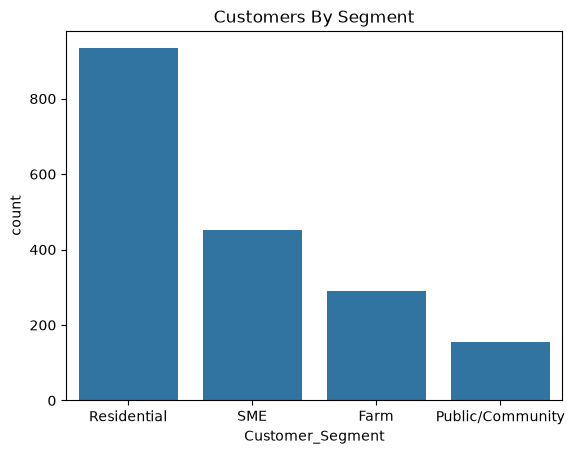

In [2016]:
sns.countplot(
    data=df,
    x="Customer_Segment")

plt.title("Customers By Segment")

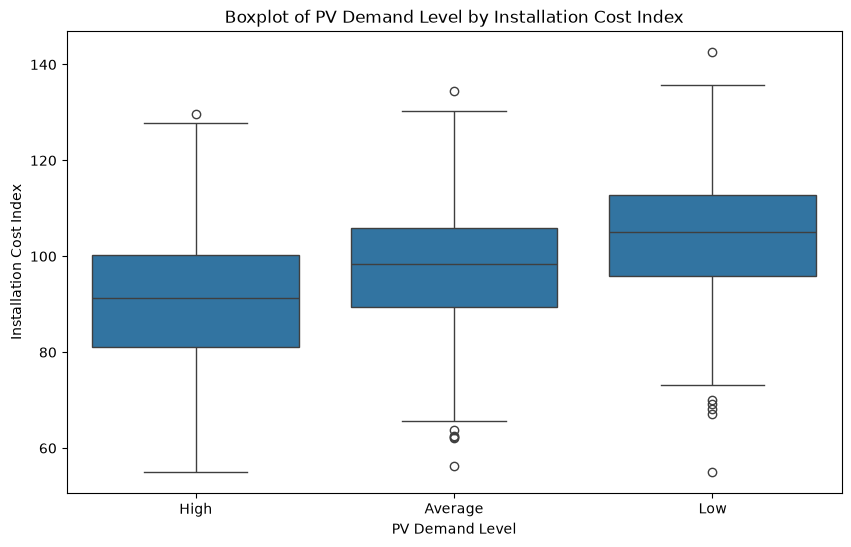

In [2017]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["PV_Demand_Level"],
    y= df["Install_Cost_Ind"]
)
   

plt.title("Boxplot of PV Demand Level by Installation Cost Index" )
plt.xlabel("PV Demand Level")
plt.ylabel("Installation Cost Index")

plt.show()

Show analysis of the Target - PV_Demand_Level

In [2018]:
df["PV_Demand_Level"].value_counts(normalize=True)

PV_Demand_Level
Average    0.475696
High       0.263790
Low        0.260513
Name: proportion, dtype: float64

Text(0.5, 1.0, 'PV Demand Level')

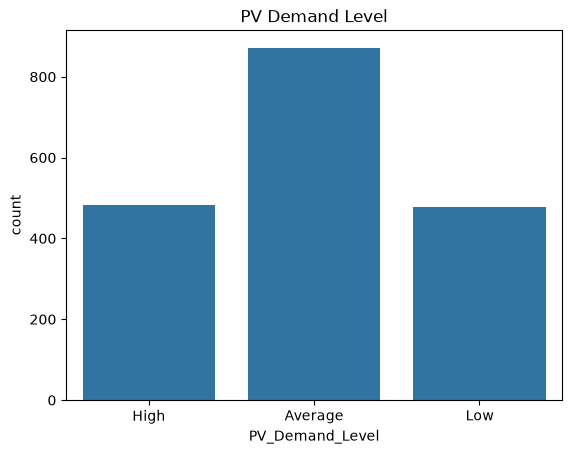

In [2019]:
sns.countplot(
    data=df,
    x="PV_Demand_Level")

plt.title("PV Demand Level")

The PV_Demand_Level is the Target class.  

The above chart shows it's reasonably balanced, reducing the chances of model bias during the Machine Learning Section.


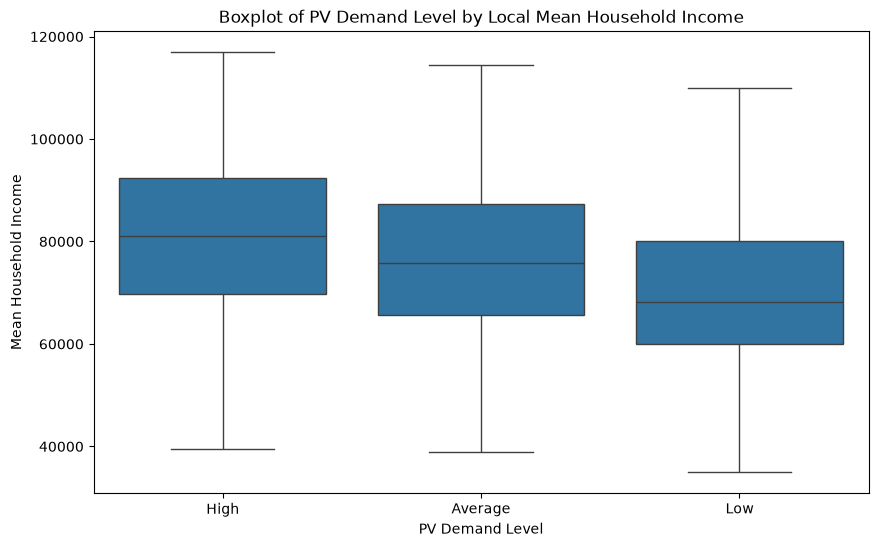

In [2020]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["PV_Demand_Level"],
    y= df["Local_Mean_Income"]
)
   

plt.title("Boxplot of PV Demand Level by Local Mean Household Income" )
plt.xlabel("PV Demand Level")
plt.ylabel("Mean Household Income")

plt.show()

The above Boxplot suggests that higher Local Mean Household Income is associated with a higher PV demand level

<Axes: xlabel='Local_Mean_Income', ylabel='Proj_PV_Install_Capacity'>

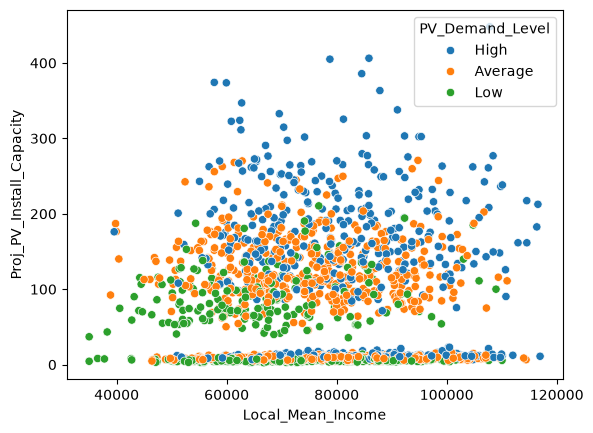

In [2021]:
sns.scatterplot(
    data = df,
    x= "Local_Mean_Income",
    y = "Proj_PV_Install_Capacity",
    hue = "PV_Demand_Level"
)

The scatterplot does not suggest a strong relationship between Local Mean Household income and Projected PV Installation Capacity.

However some separation is evident.  High demand observations tend to be associated with larger projected installation capacities.  
    

In [2022]:
# create a pivot table
pivot = pd.pivot_table (
    df,
    values="Install_Cost_Ind",
    index="PV_Demand_Level",
    columns="Customer_Segment",
    aggfunc="count",
    margins=True,
    margins_name="Total"
)
pivot

Customer_Segment,Farm,Public/Community,Residential,SME,Total
PV_Demand_Level,,,,,
Average,131,73,456,211,871
High,114,52,177,140,483
Low,45,31,300,101,477
Total,290,156,933,452,1831


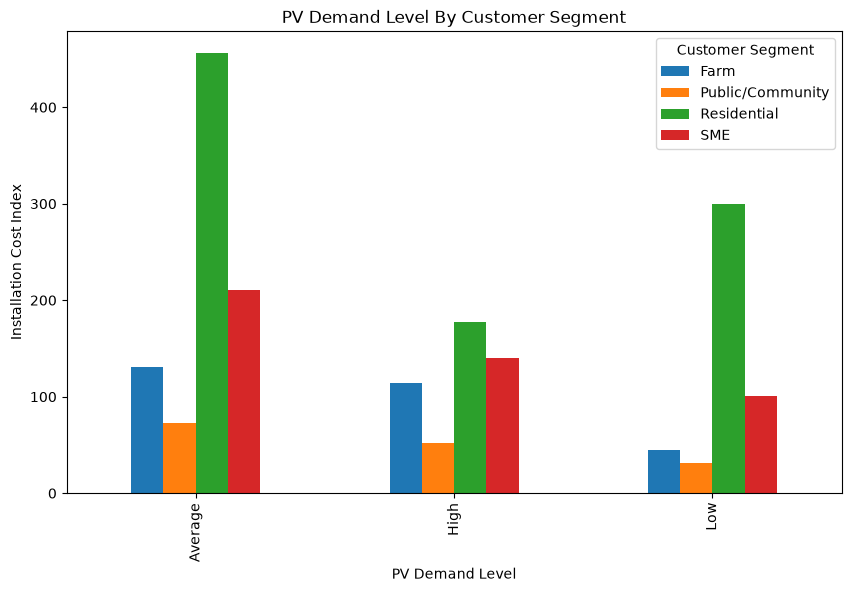

In [2023]:
pivot_chart = pivot.drop(
    index="Total",
    errors="ignore").drop(
    columns="Total",
    errors="ignore")

pivot_chart.plot(
    kind="bar",
    figsize=(10,6))

plt.title("PV Demand Level By Customer Segment")
plt.xlabel("PV Demand Level")
plt.ylabel("Installation Cost Index")
plt.legend(title="Customer Segment")

plt.show()

In [2024]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity
Forecast_Year,1.000000,0.242955,-0.351843,0.019872,-0.014855,-0.010519,0.013729,-0.552683,-0.027184,0.179113
Local_Mean_Income,0.242955,1.000000,-0.054695,0.171211,-0.050113,0.522426,-0.062501,-0.105650,0.510011,0.006305
Electric_Cost,-0.351843,-0.054695,1.000000,0.001090,0.017417,0.041131,-0.034593,0.186394,0.044785,-0.005888
Solar_Resource,0.019872,0.171211,0.001090,1.000000,0.016313,0.215765,0.019854,0.035947,0.146522,0.066764
Site_Suitability,-0.014855,-0.050113,0.017417,0.016313,1.000000,-0.109987,0.274617,-0.041191,-0.109692,0.483911
Grid_Accessibility,-0.010519,0.522426,0.041131,0.215765,-0.109987,1.000000,-0.081425,0.040909,0.459382,-0.070977
Grant_Support,0.013729,-0.062501,-0.034593,0.019854,0.274617,-0.081425,1.000000,-0.069552,-0.095247,0.554401
Install_Cost_Ind,-0.552683,-0.105650,0.186394,0.035947,-0.041191,0.040909,-0.069552,1.000000,0.041226,-0.235236
Planning_Constraint_Ind,-0.027184,0.510011,0.044785,0.146522,-0.109692,0.459382,-0.095247,0.041226,1.000000,-0.140294
Proj_PV_Install_Capacity,0.179113,0.006305,-0.005888,0.066764,0.483911,-0.070977,0.554401,-0.235236,-0.140294,1.000000


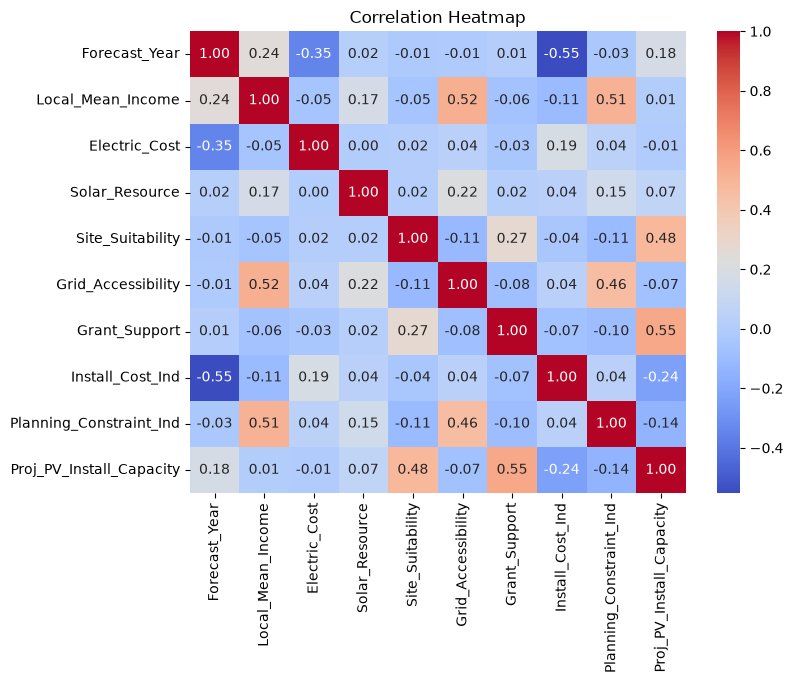

In [2025]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    corr_matrix,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Heatmap")

plt.show()

From the above correaltion heatmap, we can see positive correlation between Local_Mean_income (r=0.52) and Grid_Accessibility.

We also see Grant_Support shows a moderate positive relationship (r=0.55) and Projected_PV_Installation_Capacity, suggesting that larger grants may encourage larger-scale solar installations.

Site_Suitability also provides a moderate positive relationship (r=0.48) to Projected_PV_Installation_Capacity, suggesting that more suitable locations will have a higher installation capacity

Forecast_Year shows a moderate negative relationship (r= -0.55) with Installation_Cost_Index, this suggests that costs are projected to decrease over time.  

Installation_Cost_Index also shows a weak negative relationship (r= -0.24) with Projected_PV_Installation_Capacity, suggesting that higher costs may reduce the size of of PV installations  

    

Create a Distribution Chart of Local_Mean_Income and check normality

In [2026]:
from scipy import stats 
from scipy.stats import norm # for normality test 

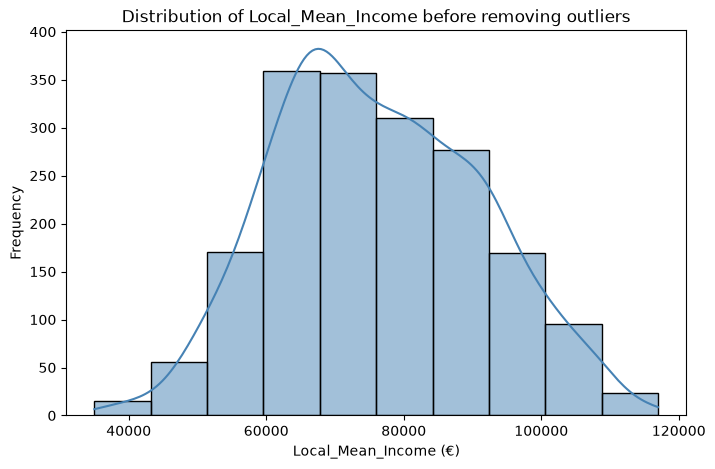

In [2027]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df,
    x="Local_Mean_Income",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Local_Mean_Income before removing outliers")
plt.xlabel("Local_Mean_Income (€)")
plt.ylabel("Frequency")


plt.show()

#### Check Normality (using Shapiro_Wilk_test) 

In [2028]:
stat, p_value = stats.shapiro(df["Local_Mean_Income"])

print(stat,p_value)

0.9917083182324385 1.1220497194861754e-08


In [2029]:
if p_value >= 0.05:
    print("Sample appears to be normally distributed.")
else:
    print("Sample does not appear to be normally distributed.")
    

Sample does not appear to be normally distributed.


Drop Outliers in Local_Mean_Income using the IQR Method

In [2030]:
Before_Removal = len(df["Local_Mean_Income"])
print(Before_Removal)

1831


In [2031]:
Q1 = df["Local_Mean_Income"].quantile(0.25)
Q3 = df["Local_Mean_Income"].quantile(0.75)
IQR = Q3 - Q1
print("Q1= " , Q1)
print("Q3= " , Q3)
print("IQR= " , IQR)

Q1=  64945.975
Q3=  87355.6
IQR=  22409.625000000007


In [2032]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("lower_bound =  " , lower_bound)
print("upper_bound =  " , upper_bound)

lower_bound =   31331.537499999984
upper_bound =   120970.03750000002


Remove the lower and upper bounds

In [2033]:
df = df[
    (df["Local_Mean_Income"] >= lower_bound) &
     (df["Local_Mean_Income"] <= upper_bound)
      ]

In [2034]:
df["Local_Mean_Income"].describe()

count      1831.000000
mean      76168.894992
std       15064.169327
min       35000.000000
25%       64945.975000
50%       75084.860000
75%       87355.600000
max      116976.500000
Name: Local_Mean_Income, dtype: float64

In [2035]:
After_Removal = len(df["Local_Mean_Income"])
print(After_Removal)

1831


The IQR method was applied to identify potential outliers with Local_Mean_Income.

However, no observations fell outside the lower and upper IQR thresholds.  This suggests that i had already addressed the outliers earlier in data cleaning stage and no further removal was required.  